In [3]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [4]:
house_price=pd.read_csv("HousePricePredictiona1.csv")
house_price.head()

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
0,0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0,208500.0
1,1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0,181500.0
2,2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0,223500.0
3,3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0,140000.0
4,4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0,250000.0


<Axes: xlabel='SalePrice', ylabel='YearBuilt'>

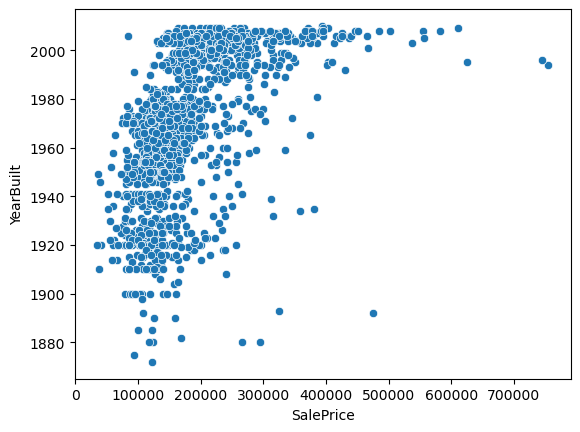

In [6]:
#VISUALIZE IN GRAPH FORM

sns.scatterplot(x=house_price["SalePrice"],y=house_price["YearBuilt"])

In [86]:
# DROP KARENGE SALEPRICE KO PHIR Y ME STORE KARENGE
x = house_price.drop(columns=["SalePrice"])

# HAME ME FUTURE ME SALEPRICE KO HI PREDICT KRNA H ISLIYE HAM Y ME USKO STORE KR LETE H
y = house_price["SalePrice"]

# SALEPRICE ME JO BHI VALUES NULL H USKO HAM MEAN VALUE SE FILL KR DENGE
house_price["SalePrice"] = house_price["SalePrice"].fillna(house_price["SalePrice"].mean())

# JO BHI ROW ME NULL VALUES HOGI US ROW KO DLT KR DENGE
x=x.dropna()
y = y.fillna(y.mean())
# y ko bhi same rows par align kar do
y = y.loc[x.index] 

x.tail()


,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF
2914,2914,160,RM,1936,Inside,Twnhs,7,1970,1970,CemntBd,0.0,546.0
2915,2915,160,RM,1894,Inside,TwnhsE,5,1970,1970,CemntBd,0.0,546.0
2916,2916,20,RL,20000,Inside,1Fam,7,1960,1996,VinylSd,0.0,1224.0
2917,2917,85,RL,10441,Inside,1Fam,5,1992,1992,HdBoard,0.0,912.0
2918,2918,60,RL,9627,Inside,1Fam,5,1993,1994,HdBoard,0.0,996.0


In [87]:
#JO BHI VALUES STRING ME H USKO INTEGER ME CONVERT KR DENGE IS LINE SE TAAKI COMPUTER KO INTEGERS VALUE MILE
x = pd.get_dummies(x, drop_first=True)

In [88]:
#TRAIN, TEST, SPLIT   SPLITING-- 80% TRAIN AND 20% TEST

from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)   #TEST SIZE=20%  RANDOM_STATE KOI RANDOM VALUE H
x_test.head()

,Id,MSSubClass,LotArea,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF2,TotalBsmtSF,MSZoning_FV,MSZoning_RH,...,Exterior1st_CemntBd,Exterior1st_HdBoard,Exterior1st_ImStucc,Exterior1st_MetalSd,Exterior1st_Plywood,Exterior1st_Stone,Exterior1st_Stucco,Exterior1st_VinylSd,Exterior1st_Wd Sdng,Exterior1st_WdShing
178,178,20,17423,5,2008,2009,0.0,2216.0,False,False,...,False,False,False,False,False,False,False,True,False,False
678,678,20,11844,5,2008,2008,0.0,2046.0,False,False,...,False,False,False,False,False,False,False,True,False,False
2878,2878,50,10164,5,1939,1950,0.0,992.0,False,False,...,False,False,False,False,False,False,False,True,False,False
2691,2691,20,7733,5,2005,2005,0.0,1142.0,False,False,...,False,False,False,False,False,False,False,True,False,False
1898,1898,30,8574,8,1916,2000,0.0,816.0,False,False,...,False,False,False,False,False,False,True,False,False,False


In [89]:
#TRAIN MODEL

from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [90]:
#PREDICTED VALUE
y_pred=model.predict(x_test)
y_pred


array([250850.44657111, 233284.89919762, 159018.89188985, 194346.2832231 ,
       174658.5668287 , 213224.16232657, 129547.22579099, 161615.44713657,
       225047.78685144, 163848.51097372, 199957.23258341, 176961.09665838,
       159083.55896716, 206235.87070993, 173739.36540859, 194946.16973102,
       186539.5222478 , 177274.01851729, 154603.71932531, 165823.64393113,
       173317.03483357, 187217.59849799, 199778.82201222, 186120.00690328,
       209684.95173202, 146773.15631214, 217854.93317401, 151892.27628441,
       170064.69802191, 170613.74475442, 213875.11645489, 141958.81291886,
       226411.21845914, 181729.2194891 , 133824.71105664, 202319.25128796,
       164201.17096609, 165779.14190517, 147396.96521085, 166805.51859712,
       229788.30135292, 194273.84013402, 205636.74508259, 211496.29438673,
       198859.73605084, 265759.19232802, 187961.57801455, 208639.41895878,
       227042.33587751, 155978.4514354 , 230591.79361263, 147296.36686922,
       205331.52647156, 1

In [91]:
#TESTING VALUE
y_test

178     501837.00000
678     372500.00000
2878    180921.19589
2691    180921.19589
1898    180921.19589
            ...     
1221    134000.00000
542     213250.00000
2319    180921.19589
1644    180921.19589
1591    180921.19589
Name: SalePrice, Length: 583, dtype: float64

In [92]:
#EVALUATION METRICES

#R-SQUARED:
from sklearn.metrics import r2_score
r2=r2_score(y_test,y_pred)
print("r_squared",r2)

#ADJUSTED R-SQUARED:
n=x_test.shape[0]
p=x_test.shape[1]
adjusted_r2=1-((1-r2)*(n-1)/(n-p-1))
print("adjusted r^2",adjusted_r2)

r_squared 0.3463684320721766
adjusted r^2 0.3058146486605964
